# Experiment 3: Time Series Data Analysis
## Analysis and Visualization of Stock Market Data

**Dataset:** `Stock_Prices.csv`  
**Company:** Apple Inc. (AAPL)  
**Source:** User-provided Kaggle S&P 500 stock dataset (`AAPL_data.csv`), renamed to `Stock_Prices.csv`.

### Aim
To analyse historical stock prices, visualize trends and patterns, study relationships between variables, and forecast future closing prices using an ARIMA model.

**Note:** This dataset contains historical observations from 2013 to 2018. The forecast is a learning exercise, not financial advice or a prediction for current trading.

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv("Stock_Prices.csv")

# Display the first five rows
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


## 1. Explore the dataset

In [2]:
# Understand the structure and contents of the dataset
print("Shape of dataset:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe())

print("\\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (1259, 7)
\nColumn names:
['date', 'open', 'high', 'low', 'close', 'volume', 'Name']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    1259 non-null   str    
 1   open    1259 non-null   float64
 2   high    1259 non-null   float64
 3   low     1259 non-null   float64
 4   close   1259 non-null   float64
 5   volume  1259 non-null   int64  
 6   Name    1259 non-null   str    
dtypes: float64(4), int64(1), str(2)
memory usage: 86.2 KB
\nStatistical summary:


,open,high,low,close,volume
count,1259.000000,1259.000000,1259.000000,1259.000000,1.259000e+03
mean,109.055429,109.951118,108.141589,109.066698,5.404790e+07
std,30.549220,30.686186,30.376224,30.556812,3.346835e+07
min,55.424200,57.085700,55.014200,55.789900,1.147592e+07
25%,84.647800,85.334950,84.250650,84.830650,2.969438e+07
50%,108.970000,110.030000,108.050000,109.010000,4.566893e+07
75%,127.335000,128.100000,126.290000,127.120000,6.870872e+07
max,179.370000,180.100000,178.250000,179.260000,2.668336e+08


\nMissing values:
date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64


## 2. Convert the date column and prepare time series data

In [3]:
# Convert date into datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort data by date and use date as the index
df = df.sort_values("date")
df = df.set_index("date")

print("Date column data type:", df.index.dtype)
print("Date range:", df.index.min(), "to", df.index.max())
df.head()

Date column data type: datetime64[us]
Date range: 2013-02-08 00:00:00 to 2018-02-07 00:00:00


,open,high,low,close,volume,Name
date,,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL


## 3. Visualize historical stock prices

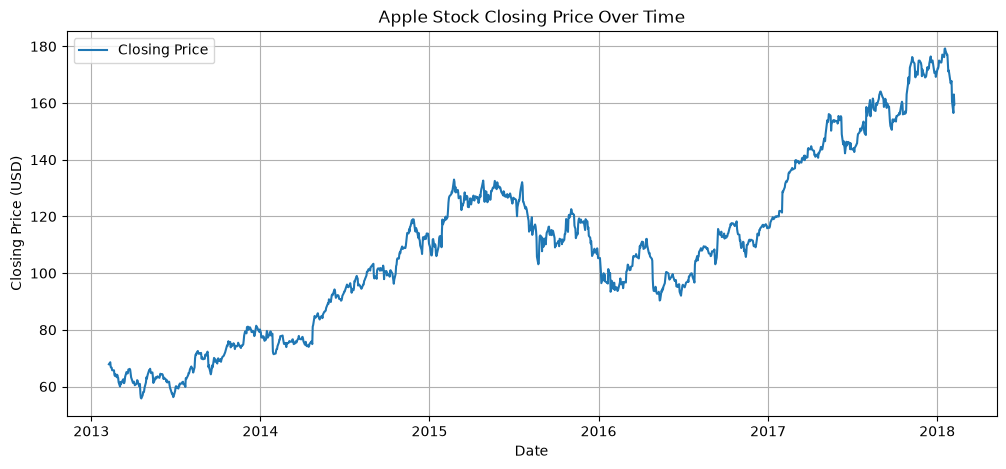

In [4]:
# Plot daily closing prices
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["close"], label="Closing Price")
plt.title("Apple Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 4. Calculate and plot moving averages

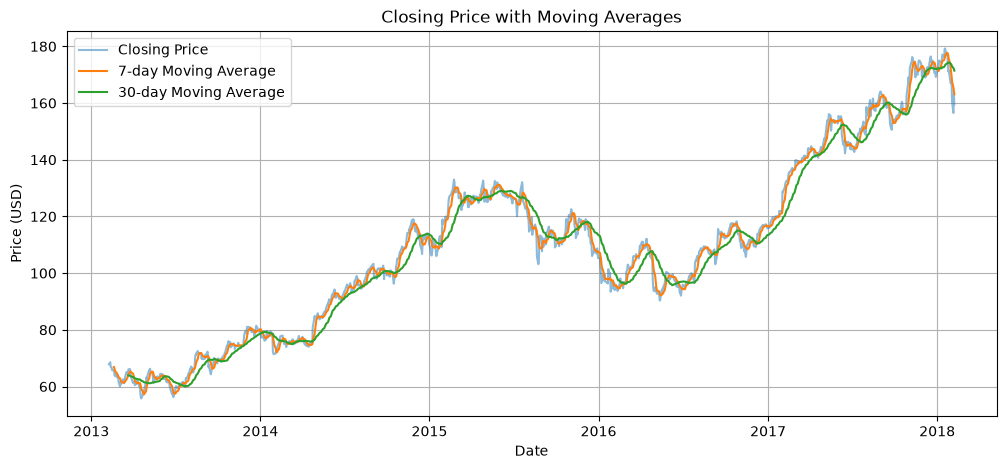

In [5]:
# Calculate 7-day and 30-day moving averages
df["MA_7"] = df["close"].rolling(window=7).mean()
df["MA_30"] = df["close"].rolling(window=30).mean()

# Plot closing price with moving averages
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["close"], label="Closing Price", alpha=0.5)
plt.plot(df.index, df["MA_7"], label="7-day Moving Average")
plt.plot(df.index, df["MA_30"], label="30-day Moving Average")
plt.title("Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 5. Seasonality analysis

Stock markets trade on business days, so the data does not contain every calendar day. We compare:
- Average closing price by day of the week.
- Average closing price by month.
- Average closing price by year.

These plots help us inspect periodic patterns. They do not prove that a pattern will repeat in the future.

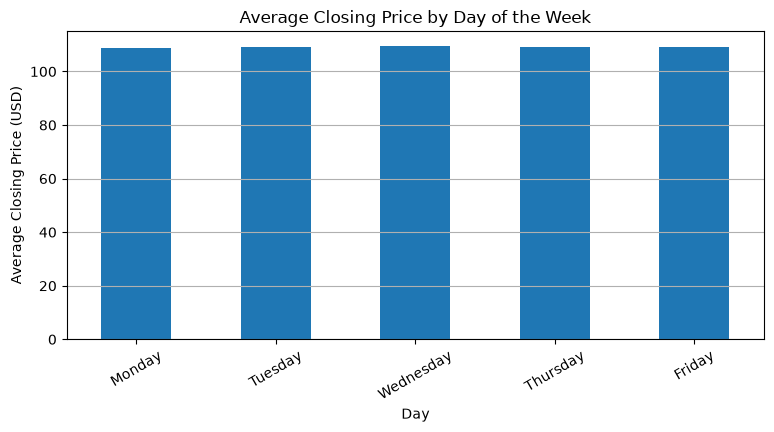

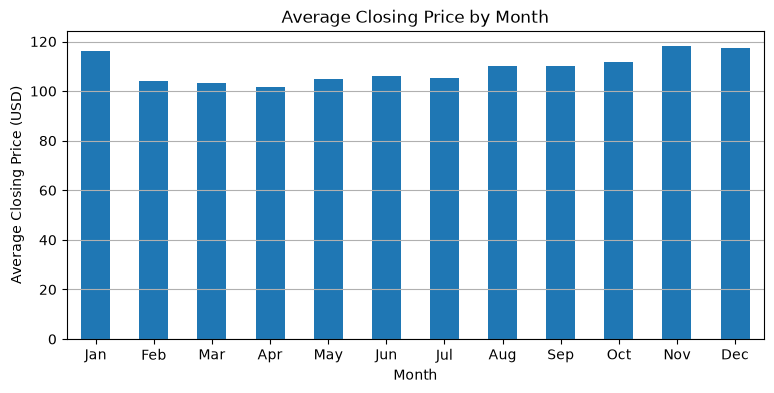

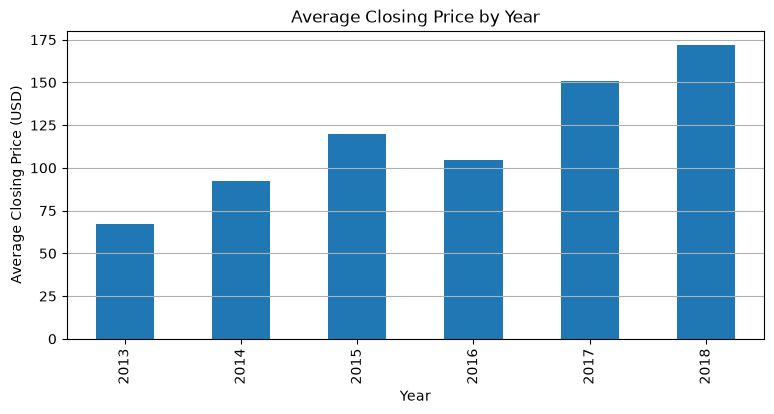

In [6]:
# Create calendar-related columns
season = df.copy()
season["Weekday"] = season.index.day_name()
season["Month"] = season.index.month
season["Month_Name"] = season.index.strftime("%b")
season["Year"] = season.index.year

# Average closing price by weekday
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekday_avg = season.groupby("Weekday")["close"].mean().reindex(weekday_order)

plt.figure(figsize=(9, 4))
weekday_avg.plot(kind="bar")
plt.title("Average Closing Price by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Closing Price (USD)")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()

# Average closing price by month
month_avg = season.groupby("Month")["close"].mean()

plt.figure(figsize=(9, 4))
month_avg.plot(kind="bar")
plt.title("Average Closing Price by Month")
plt.xlabel("Month")
plt.ylabel("Average Closing Price (USD)")
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                       "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)
plt.grid(axis="y")
plt.show()

# Average closing price by year
year_avg = season.groupby("Year")["close"].mean()

plt.figure(figsize=(9, 4))
year_avg.plot(kind="bar")
plt.title("Average Closing Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Closing Price (USD)")
plt.grid(axis="y")
plt.show()

## 6. Correlation between stock price and trading volume

Correlation matrix:


,close,volume
close,1.00000,-0.62029
volume,-0.62029,1.00000


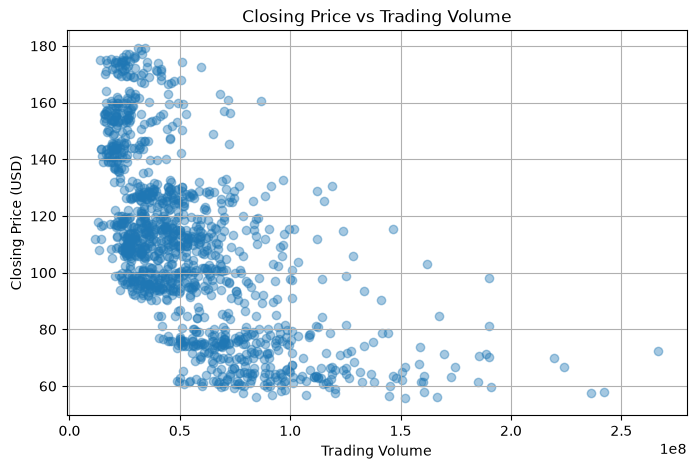

In [7]:
# Calculate correlation between closing price and trading volume
correlation = df[["close", "volume"]].corr()
print("Correlation matrix:")
display(correlation)

# Plot the relationship
plt.figure(figsize=(8, 5))
plt.scatter(df["volume"], df["close"], alpha=0.4)
plt.title("Closing Price vs Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.show()

## 7. Forecast future closing prices using ARIMA

We use an ARIMA(5, 1, 0) model as a straightforward forecasting example. The data is split chronologically: the last 20% is kept for testing, and the earlier 80% is used for training. We compare the forecast with actual test closing prices using MAE and RMSE.

c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\P

Mean Absolute Error (MAE): 24.32
Root Mean Squared Error (RMSE): 27.248


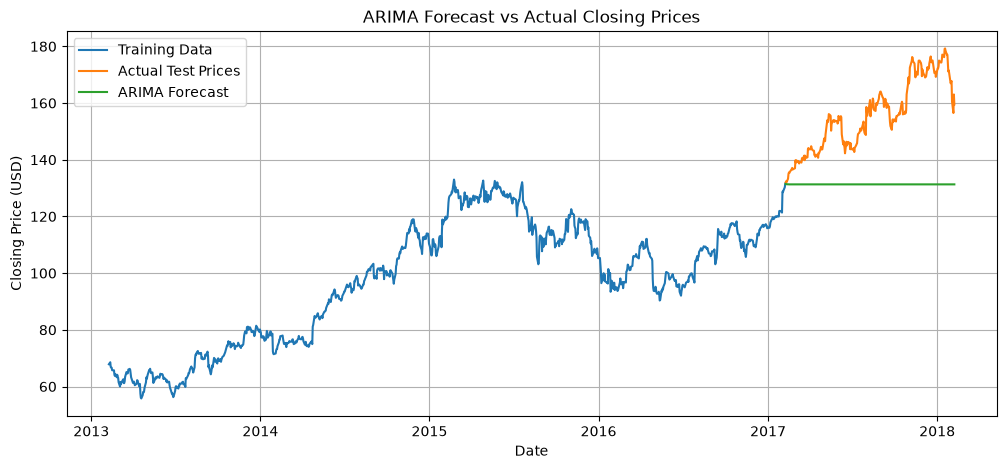

In [8]:
# Install/import ARIMA from statsmodels
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the closing price series
close_prices = df["close"].astype(float)

# Split data in chronological order (80% train, 20% test)
split_point = int(len(close_prices) * 0.8)
train = close_prices.iloc[:split_point]
test = close_prices.iloc[split_point:]

# Fit ARIMA model
model = ARIMA(train, order=(5, 1, 0))
model_fit = model.fit()

# Forecast the test period
test_forecast = model_fit.forecast(steps=len(test))
test_forecast.index = test.index

# Evaluate forecast accuracy
mae = mean_absolute_error(test, test_forecast)
rmse = np.sqrt(mean_squared_error(test, test_forecast))

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))

# Plot actual and predicted prices
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test Prices")
plt.plot(test_forecast.index, test_forecast, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

## 8. Forecast the next 30 trading days

c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\P

,Forecast Closing Price
2018-02-08,159.127683
2018-02-09,158.960932
2018-02-12,159.111165
2018-02-13,159.126345
2018-02-14,159.061677
2018-02-15,159.048456
2018-02-16,159.051535
2018-02-19,159.055102
2018-02-20,159.053708
2018-02-21,159.052261


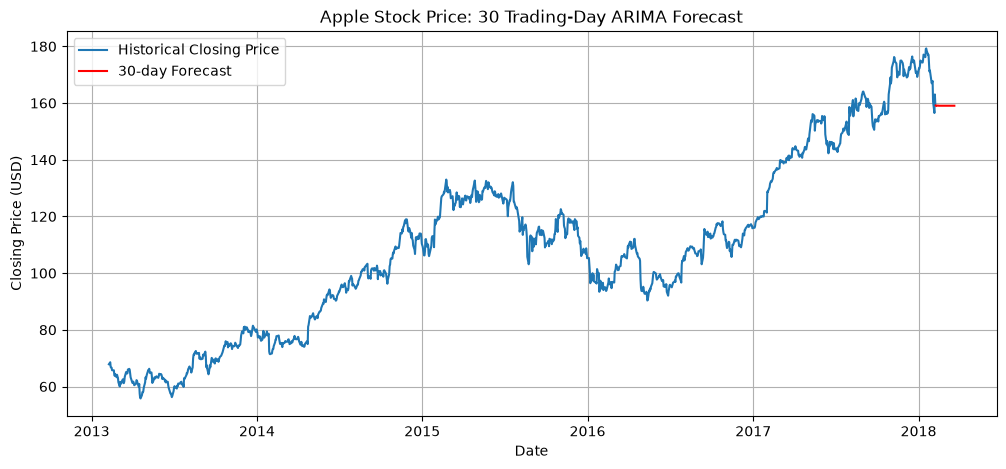

In [9]:
# Fit ARIMA on the complete series and forecast the next 30 observations
final_model = ARIMA(close_prices, order=(5, 1, 0))
final_model_fit = final_model.fit()

future_values = final_model_fit.forecast(steps=30)

# Create future business-day dates (approximate trading dates)
future_dates = pd.bdate_range(
    start=close_prices.index[-1] + pd.offsets.BDay(1),
    periods=30
)
future_forecast = pd.Series(future_values.values, index=future_dates)

# Display forecast values
display(future_forecast.to_frame(name="Forecast Closing Price"))

# Plot historical prices and future forecast
plt.figure(figsize=(12, 5))
plt.plot(close_prices.index, close_prices, label="Historical Closing Price")
plt.plot(future_forecast.index, future_forecast, label="30-day Forecast", color="red")
plt.title("Apple Stock Price: 30 Trading-Day ARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this practical, historical Apple stock data was imported and explored. The date column was converted to datetime format and used as the time-series index. Closing-price charts and moving averages were used to study trends. Weekday, monthly and yearly averages were plotted to inspect possible periodic patterns. The relationship between closing price and trading volume was examined using correlation and a scatter plot. Finally, an ARIMA model was fitted, evaluated on a chronological test set, and used to forecast the next 30 business days.

**Important:** ARIMA forecasts are based on historical values and assumptions. They cannot reliably predict unexpected market events and should not be used alone for investment decisions.